# Can an MMM Find the Truth? Calibrating a Media Mix Model with Lift Experiments

**The question.** Marketers set budgets from media-mix-model (MMM) ROI estimates, but those estimates can be badly
wrong when spend tracks demand: companies spend more *because* sales are about to be high, so a model can credit
channels for sales that would have happened anyway. Does feeding the model a small randomized experiment fix its ROI
estimates, and does that make budget decisions better?

**How it is answered.** Everything is simulated, so the true ROI and true response curve of every channel are *known*
and every estimate and every budget can be scored against the truth:

1. A 3-year weekly world, five channels, spend confounded with demand, and a **deliberately misallocated status quo**
   (so there is real room to improve: the headline metric is the share of that headroom each model recovers).
2. **Model A** naive regression, **Model B** Bayesian MMM (PyMC-Marketing), **Model C** the MMM calibrated with a
   simulated geo-lift test on Social.
3. Fixes for the failure modes found along the way: curve shape (Hill), over-attribution (ROI prior), test design
   (longer window, tests on more channels).
4. A fixed **$1M quarterly budget** optimized by each model and scored against the true curves.
5. The same pipeline on six fresh worlds with *different true parameters*, then a one-page recommendation.

> Models are fitted by `scripts/fit_study.py` and cached in `cache/`; this notebook loads them. Every number printed
> below is computed here, none is typed by hand. Code lives in `src/mmmcal/` (with tests).


In [1]:
import os
for k in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "VECLIB_MAXIMUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[k] = "1"      # one BLAS thread per sampler process; oversubscription thrashes small machines

import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.linear_model import LinearRegression

from mmmcal import study
from mmmcal.budget import budget_table, current_mix_weekly, headroom, optimise, true_fn, WEEKLY_BUDGET
from mmmcal.fit import curve_draws, get_model, hdi, roi_table
from mmmcal.geotest import DEFAULT_WASHOUT, run_geo_test
from mmmcal.world import (CHANNELS, N_EXTRA, N_TRAIN, PARAM_RANGES, STATUS_QUO_BASE_SPEND, random_world, true_roi,
                          true_weekly_response)

MAIN_SEED, ROBUST_SEEDS = study.MAIN_SEED, study.ROBUST_SEEDS
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
COL = {"true": "#111111", "naive": "#8c8c8c", "B": "#3b6ea8", "C": "#e07b24", "D": "#2a9d6f", "E": "#8d6e63", "oracle": "#7a3b8f", "H": "#c2185b"}


## 1. The simulated world

156 weeks of training data, five channels, each with its own **true** adstock decay, saturation curve and average ROI.

* **Baseline sales** = trend x (1 + seasonality + holiday spikes + an *unobserved demand shock*).
* **Spend is confounded**: planners spend ahead of peak season (3-week lead), chase last week's demand, and Social/Display
  share a campaign-flighting factor, so channel spends are highly collinear.
* **True parameters are drawn per world** from the ranges below (not fixed), so "robust across worlds" means different
  markets, not just different noise.
* **The status quo is deliberately misallocated**: planners over-weight Display (low ROI) and under-weight Search and Email
  (high ROI). That leaves real headroom, so a good model can *win* by reallocating. The ranges and base spends were set by
  looking only at the true curves, before any model was fitted.
* The model-side functional forms differ from the truth (truth: Hill curves with TV S-shaped, infinite adstock, trend x
  season multiplicative; default model: logistic curves, truncated adstock, additive terms), as in real life.


In [2]:
rng_table = pd.DataFrame({c: {"true ROI range": f"{r['roi'][0]}-{r['roi'][1]}", "adstock decay": f"{r['alpha'][0]}-{r['alpha'][1]}",
                               "curve shape (1 = concave)": f"{r['shape'][0]}-{r['shape'][1]}",
                               "status-quo weekly spend": f"${STATUS_QUO_BASE_SPEND[c]:,}"} for c, r in PARAM_RANGES.items()}).T
display(rng_table)

world = random_world(MAIN_SEED)
df = world["df"]; train = df.iloc[:N_TRAIN]
TRUE_ROI = pd.Series(true_roi(world))
mk = sum(train[f"contrib_{c}"] for c in CHANNELS)
cur = current_mix_weekly(train)
marg = {c: (true_weekly_response(world, c, cur[c] + 1000) - true_weekly_response(world, c, cur[c])) / 1000 for c in CHANNELS}
main_world = pd.DataFrame({
    "true avg ROI": TRUE_ROI, "true MARGINAL ROI at current spend": pd.Series(marg),
    "current weekly spend ($k)": pd.Series(cur) / 1e3, "corr(spend, baseline demand)": train[CHANNELS].corrwith(train["baseline"]),
}).round(2)
display(main_world)
print(f"Main world (seed {MAIN_SEED}): marketing drives {mk.sum()/train.sales.sum():.1%} of sales; headroom (true curves vs current mix, "
      f"halve/double rule) = {headroom(world, train):.1%}")


,true ROI range,adstock decay,curve shape (1 = concave),status-quo weekly spend
TV,1.0-2.0,0.45-0.75,1.2-2.0,"$20,000"
Search,3.0-5.0,0.0-0.2,1.0-1.0,"$5,000"
Social,1.5-2.5,0.2-0.4,1.0-1.0,"$11,000"
Display,0.3-0.8,0.3-0.5,1.0-1.0,"$34,000"
Email,5.0-10.0,0.0-0.2,1.0-1.0,"$3,000"


,true avg ROI,true MARGINAL ROI at current spend,current weekly spend ($k),"corr(spend, baseline demand)"
TV,1.36,1.30,19.14,0.77
Search,4.85,2.46,5.07,0.70
Social,1.90,1.05,10.81,0.65
Display,0.37,0.21,38.57,0.72
Email,9.82,3.77,3.34,0.45


Main world (seed 1): marketing drives 17.8% of sales; headroom (true curves vs current mix, halve/double rule) = 20.9%


Headroom across 30 sampled worlds: median 16.3%, 10th-90th percentile 12.3%-20.9%


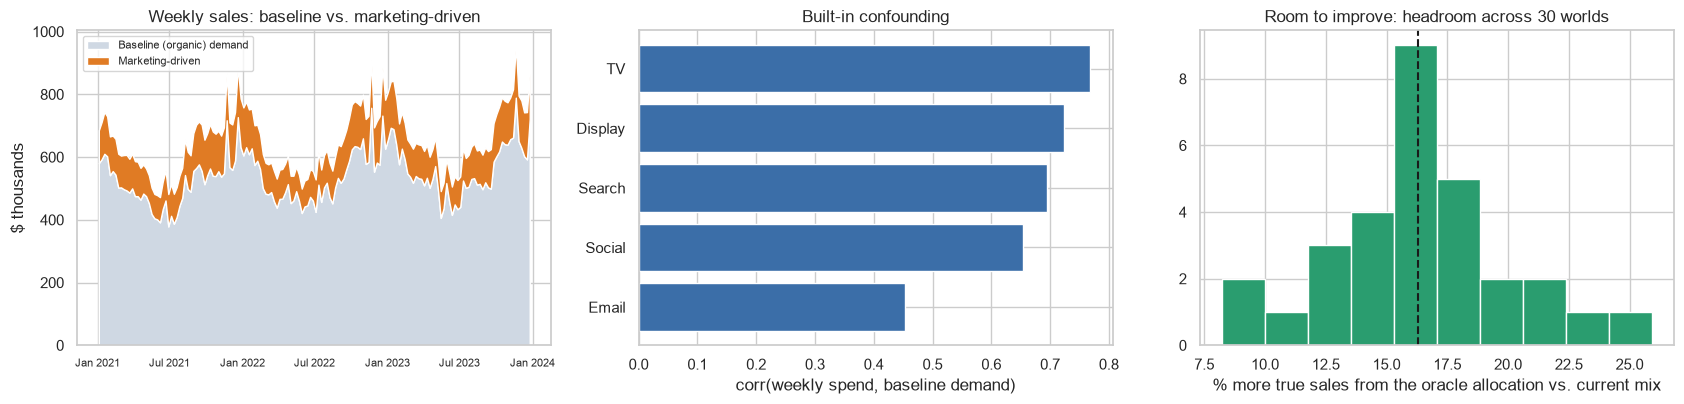

In [3]:
hs = pd.Series({s: headroom(random_world(s), random_world(s)["df"].iloc[:N_TRAIN]) for s in range(1, 31)})
print(f"Headroom across 30 sampled worlds: median {hs.median():.1%}, 10th-90th percentile {hs.quantile(.1):.1%}-{hs.quantile(.9):.1%}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].stackplot(train["date"], train["baseline"] / 1e3, mk / 1e3, labels=["Baseline (organic) demand", "Marketing-driven"], colors=["#cfd8e3", "#e07b24"])
ax[0].set_title("Weekly sales: baseline vs. marketing-driven"); ax[0].set_ylabel("$ thousands"); ax[0].legend(loc="upper left", fontsize=8)
ax[0].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); ax[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y")); ax[0].tick_params(axis="x", labelsize=8)
corr = train[CHANNELS].corrwith(train["baseline"]).sort_values()
ax[1].barh(corr.index, corr.values, color="#3b6ea8"); ax[1].set_title("Built-in confounding"); ax[1].set_xlabel("corr(weekly spend, baseline demand)")
ax[2].hist(hs * 100, bins=10, color="#2a9d6f", edgecolor="white"); ax[2].axvline(hs.median() * 100, color="k", ls="--")
ax[2].set_title("Room to improve: headroom across 30 worlds"); ax[2].set_xlabel("% more true sales from the oracle allocation vs. current mix")
plt.tight_layout(); plt.savefig(FIG / "01_world.png", dpi=150, bbox_inches="tight"); plt.show()


## 2. Model A: naive regression

OLS of weekly sales on weekly spend: the "ROI = coefficient" shortcut, with no adstock, saturation or seasonality control.


In [4]:
def naive_roi(train_df):
    lr = LinearRegression().fit(train_df[CHANNELS], train_df["sales"])
    return pd.Series(dict(zip(CHANNELS, lr.coef_)))

err = lambda est, truth: abs(est - truth) / truth
NAIVE = naive_roi(train)
display(pd.DataFrame({"true ROI": TRUE_ROI, "naive ROI": NAIVE, "naive / true": NAIVE / TRUE_ROI}).round(2))
print(f"Mean absolute % ROI error, naive: {err(NAIVE, TRUE_ROI).mean():.0%}")


,true ROI,naive ROI,naive / true
TV,1.36,4.33,3.17
Search,4.85,14.77,3.05
Social,1.90,0.17,0.09
Display,0.37,0.55,1.49
Email,9.82,20.14,2.05


Mean absolute % ROI error, naive: 133%


## 3. Geo-lift tests

After the training years, a geo-lift test switches one channel **off** in half the regions (paired by size, randomized within
pairs; 10 regions, 4% weekly regional noise). The effect is measured by difference-in-differences against the last 8
pre-test weeks, with a standard error from the region-level spread.

**Test window.** Because of adstock, a cut takes weeks to develop fully: a slow channel like TV shows well under half of its
steady-state effect in the first week. So the test runs 8 weeks and **only the last 4 are analysed** (the first 4 are a washout).
The comparison below shows how much that matters for TV in this world.


In [5]:
OFF, HALF = study.all_tests(MAIN_SEED, world)
rows = []
for wo in (0, DEFAULT_WASHOUT):
    g = run_geo_test(world, "TV", seed=MAIN_SEED + 1000 + 101, noise_sd=0.0, washout=wo)       # noise-free, to isolate the bias
    full_cut = df["contrib_TV"].iloc[N_TRAIN + wo:N_TRAIN + N_EXTRA].mean()
    rows.append({"analysed weeks": f"{N_EXTRA - wo} (washout {wo})", "share of a full cut's effect measured": -g["effect"] / full_cut})
display(pd.DataFrame(rows).set_index("analysed weeks").round(2).rename_axis(f"TV (decay {world['params']['TV']['alpha']:.2f})"))

power = pd.DataFrame({c: {"switch off": abs(OFF[c]["truth_effect_in_window"]) / OFF[c]["se"],
                          "halve spend": abs(HALF[c]["truth_effect_in_window"]) / HALF[c]["se"]} for c in CHANNELS}).round(2)
display(power.rename_axis("|true effect| / measurement SE"))
g = OFF["Social"]
print(f"\nSocial off-test: measured {g['effect']:,.0f}/wk vs. true {g['truth_effect_in_window']:,.0f}/wk (SE {g['se']:,.0f}, t = {g['effect']/g['se']:.1f})")
n_wrong = sum(t["wrong_sign"] for t in [*OFF.values(), *HALF.values()])
print(f"Tests with a wrong-sign measured lift (pure noise) in this world: {n_wrong} of 10 -> passed to the model as 'indistinguishable from zero'")


,share of a full cut's effect measured
TV (decay 0.66),
8 (washout 0),0.64
4 (washout 4),0.89


,TV,Search,Social,Display,Email
|true effect| / measurement SE,,,,,
switch off,1.60,1.35,2.13,1.06,3.53
halve spend,1.14,0.72,0.65,0.70,1.70



Social off-test: measured -20,391/wk vs. true -18,499/wk (SE 8,696, t = -2.3)
Tests with a wrong-sign measured lift (pure noise) in this world: 2 of 10 -> passed to the model as 'indistinguishable from zero'


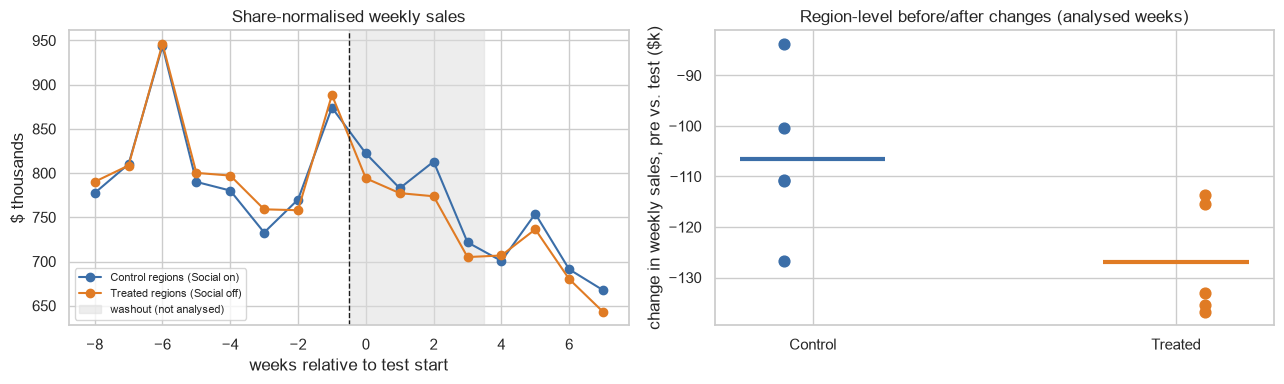

In [6]:
p = g["panel"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for t, lab, c in [(False, "Control regions (Social on)", "#3b6ea8"), (True, "Treated regions (Social off)", "#e07b24")]:
    s = p[p.treated == t].groupby("week").y.mean() / 1e3
    ax[0].plot(s.index - N_TRAIN, s.values, marker="o", label=lab, color=c)
ax[0].axvline(-0.5, color="k", ls="--", lw=1); ax[0].axvspan(-0.5, DEFAULT_WASHOUT - 0.5, color="#ddd", alpha=0.5, label="washout (not analysed)")
ax[0].set_title("Share-normalised weekly sales"); ax[0].set_xlabel("weeks relative to test start"); ax[0].set_ylabel("$ thousands"); ax[0].legend(fontsize=8)
an = p[~((p.week >= N_TRAIN) & (p.week < N_TRAIN + DEFAULT_WASHOUT))]
d = an.groupby(["region", "treated", "post"]).y.mean().unstack("post"); d["did"] = (d[True] - d[False]) / 1e3; dd = d.reset_index()
for t, c, off in [(False, "#3b6ea8", -0.08), (True, "#e07b24", 0.08)]:
    v = dd[dd.treated == t].did.values
    ax[1].scatter(np.full(len(v), float(t)) + off, v, color=c, s=60); ax[1].hlines(v.mean(), float(t) - 0.2, float(t) + 0.2, color=c, lw=3)
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["Control", "Treated"]); ax[1].set_ylabel("change in weekly sales, pre vs. test ($k)")
ax[1].set_title("Region-level before/after changes (analysed weeks)")
plt.tight_layout(); plt.savefig(FIG / "02_geo_lift_test.png", dpi=150); plt.show()


## 4. Models B and C

**Model B**: Bayesian MMM in PyMC-Marketing: geometric adstock (`l_max=8`), logistic saturation, two Fourier modes of yearly
seasonality, a linear trend and holiday dummies, default priors. The one thing the analyst cannot see is the unobserved
demand shock that planners react to.

**Model C**: identical, plus the Social off-test as a lift-test likelihood on Social's saturation curve.

ROI is the same quantity as the truth: total incremental sales attributed to a channel divided by its total spend.
Sampler: 4 chains, 2,000 tuning + 1,000 draws, target accept 0.98.


In [7]:
core = study.fit_core(MAIN_SEED, world)
B, C, D, E = core["B"], core["C"], core["D"], core["E"]
NEXT = core["_next"]

def diag(name, S):
    return (f"{name:34s} R-hat {S['max_rhat']:.3f} | min ESS {S['min_ess']:6.0f} | divergences {S['divergences']:3d}/{S['n_draws']} "
            f"| marketing share of sales {S['marketing_share']:.0%}")
print(f"(true marketing share of sales: {mk.sum()/train.sales.sum():.0%})")
for name, S in [("B: MMM", B), ("C: + Social test", C)]:
    print(diag(name, S))


(true marketing share of sales: 18%)
B: MMM                             R-hat 1.000 | min ESS    576 | divergences   8/4000 | marketing share of sales 61%
C: + Social test                   R-hat 1.010 | min ESS    656 | divergences  11/4000 | marketing share of sales 61%


## 5. ROI scoreboard: truth vs. naive vs. MMM vs. calibrated MMM

,true ROI,naive,MMM (B),calibrated (C),B 94% interval,C 94% interval
TV,1.36,4.33,0.84,0.88,0.0-3.4,0.0-3.4
Search,4.85,14.77,8.89,8.83,1.8-17.6,2.0-17.9
Social,1.90,0.17,2.42,2.31,0.1-7.0,0.8-3.7
Display,0.37,0.55,1.32,1.27,0.1-3.0,0.2-3.1
Email,9.82,20.14,79.81,80.51,22.5-280.0,21.6-310.0


,TV,Search,Social,Display,Email
abs % error,,,,,
naive,217%,205%,91%,49%,105%
MMM (B),38%,83%,27%,260%,712%
calibrated (C),36%,82%,22%,248%,720%


Mean abs % ROI error: {'naive': '133%', 'MMM (B)': '224%', 'calibrated (C)': '221%'}
Social (tested):  B 27% -> C 22%   |   Display (correlated with Social): B 260% -> C 248%   |   TV/Search/Email (untested): B 278% -> C 279%


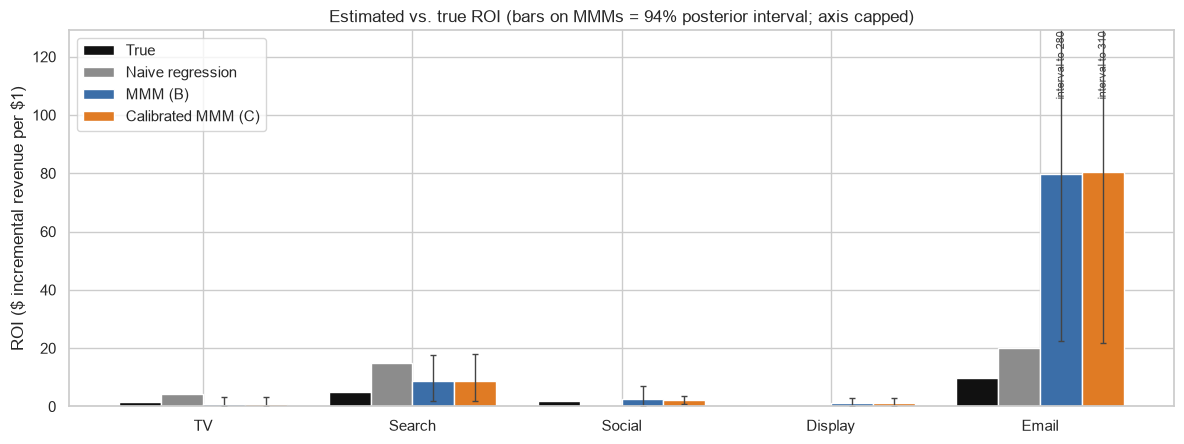

In [8]:
def pct(x):
    return f"{x:.0%}"

board = pd.DataFrame({"true ROI": TRUE_ROI, "naive": NAIVE, "MMM (B)": roi_table(B)["mean"], "calibrated (C)": roi_table(C)["mean"]}).round(2)
board["B 94% interval"] = [f"{a:.1f}-{b:.1f}" for a, b in zip(roi_table(B)["lo94"], roi_table(B)["hi94"])]
board["C 94% interval"] = [f"{a:.1f}-{b:.1f}" for a, b in zip(roi_table(C)["lo94"], roi_table(C)["hi94"])]
display(board)

errs = pd.DataFrame({"naive": err(NAIVE, TRUE_ROI), "MMM (B)": err(roi_table(B)["mean"], TRUE_ROI), "calibrated (C)": err(roi_table(C)["mean"], TRUE_ROI)})
display((errs * 100).round(0).astype(int).astype(str).add("%").T.rename_axis("abs % error"))
print("Mean abs % ROI error:", {k: pct(v) for k, v in errs.mean().items()})
others = [c for c in CHANNELS if c not in ("Social", "Display")]
print(f"Social (tested):  B {pct(errs.loc['Social','MMM (B)'])} -> C {pct(errs.loc['Social','calibrated (C)'])}   |   "
      f"Display (correlated with Social): B {pct(errs.loc['Display','MMM (B)'])} -> C {pct(errs.loc['Display','calibrated (C)'])}   |   "
      f"TV/Search/Email (untested): B {pct(errs.loc[others,'MMM (B)'].mean())} -> C {pct(errs.loc[others,'calibrated (C)'].mean())}")

YMAX = float(np.ceil(1.6 * max(TRUE_ROI.max(), NAIVE.max(), roi_table(B)["mean"].max(), roi_table(C)["mean"].max())))
fig, ax = plt.subplots(figsize=(12, 4.6)); w_ = 0.2; x = np.arange(len(CHANNELS))
ax.bar(x - 1.5 * w_, TRUE_ROI[CHANNELS], w_, color=COL["true"], label="True")
ax.bar(x - 0.5 * w_, NAIVE[CHANNELS], w_, color=COL["naive"], label="Naive regression")
for S, off, lab, col in [(B, 0.5, "MMM (B)", COL["B"]), (C, 1.5, "Calibrated MMM (C)", COL["C"])]:
    t = roi_table(S).loc[CHANNELS]
    ax.bar(x + off * w_, t["mean"], w_, color=col, label=lab, yerr=[t["mean"] - t["lo94"], t["hi94"] - t["mean"]], error_kw=dict(lw=1, capsize=2, ecolor="#444"))
    for j, c in enumerate(CHANNELS):
        if t.loc[c, "hi94"] > YMAX:
            ax.annotate(f"interval to {t.loc[c,'hi94']:.0f}", (x[j] + off * w_, YMAX - 0.3), ha="center", va="top", fontsize=8, rotation=90, color="#444")
ax.set_ylim(0, YMAX); ax.set_xticks(x); ax.set_xticklabels(CHANNELS); ax.set_ylabel(r"ROI (\$ incremental revenue per \$1)")
ax.set_title("Estimated vs. true ROI (bars on MMMs = 94% posterior interval; axis capped)"); ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig(FIG / "03_roi_comparison.png", dpi=150); plt.show()


## 6. Response curves

Weekly incremental sales as a function of weekly spend: truth vs. each model. Budget optimization follows the **slope** of
these curves, not the average ROI.


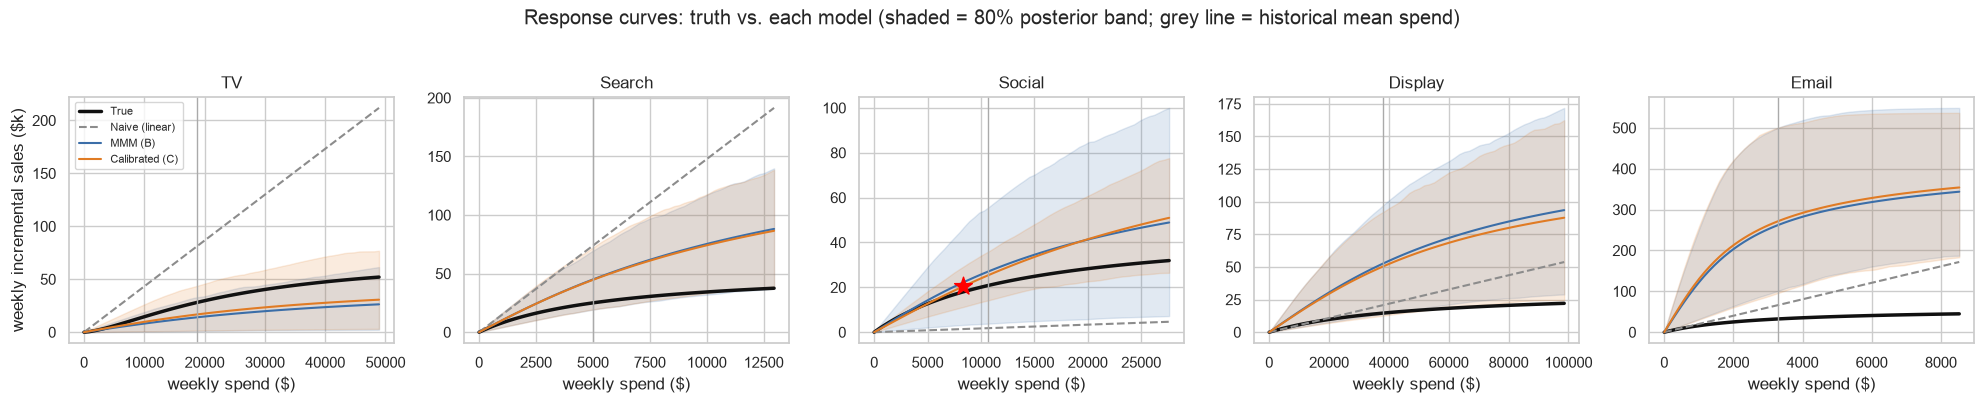

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.9))
for ax, c in zip(axes, CHANNELS):
    ms = train[c].mean(); grid = np.linspace(0, 2.6 * ms, 60)
    ax.plot(grid, [true_weekly_response(world, c, s) / 1e3 for s in grid], color=COL["true"], lw=2.5, label="True")
    ax.plot(grid, NAIVE[c] * grid / 1e3, color=COL["naive"], ls="--", label="Naive (linear)")
    for S, col, lab in [(B, COL["B"], "MMM (B)"), (C, COL["C"], "Calibrated (C)")]:
        cur_ = np.array([curve_draws(S["params"], c, s) for s in grid]) / 1e3
        ax.plot(grid, cur_.mean(1), color=col, label=lab); ax.fill_between(grid, *np.percentile(cur_, [10, 90], axis=1), color=col, alpha=0.15)
    ax.axvline(ms, color="#aaa", lw=1)
    if c == "Social":
        ax.scatter([OFF["Social"]["x"]], [-OFF["Social"]["effect"] / 1e3], marker="*", s=180, color="red", zorder=5, label="Lift test (measured)")
    ax.set_title(c); ax.set_xlabel("weekly spend ($)")
axes[0].set_ylabel("weekly incremental sales ($k)"); axes[0].legend(fontsize=8)
plt.suptitle("Response curves: truth vs. each model (shaded = 80% posterior band; grey line = historical mean spend)", y=1.03)
plt.tight_layout(); plt.savefig(FIG / "04_response_curves.png", dpi=150, bbox_inches="tight"); plt.show()


## 7. Budget optimization: how much of the headroom does each model recover?

Fixed **$1M per quarter**. Each model recommends the allocation that maximizes *its own* predicted incremental sales, subject to a
planning rule (no channel more than doubled or halved vs. the current mix). Every allocation is then scored against the **true**
response curves.

* **Headroom recovered** = (true sales of the allocation - true sales of the current mix) / (true sales of the best possible
  allocation - true sales of the current mix). 100% = as good as knowing the truth; 0% = no better than leaving the budget alone;
  negative = worse than doing nothing.
* The naive model is linear, so it pushes money to the corners.


,TV ($k),Search ($k),Social ($k),Display ($k),Email ($k),true quarterly incremental sales,vs naive (%),vs current mix (%),headroom recovered (%)
historical mix,249.0,66.0,140.0,501.0,43.0,1588047.0,-15.2,0.0,0.0
naive,460.0,132.0,70.0,251.0,87.0,1873194.0,0.0,18.0,86.0
MMM (B),124.0,132.0,258.0,399.0,87.0,1710479.0,-8.7,7.7,36.9
calibrated (C),124.0,132.0,281.0,376.0,87.0,1717344.0,-8.3,8.1,39.0
oracle,364.0,132.0,166.0,251.0,87.0,1919611.0,2.5,20.9,100.0


Calibrated MMM's budget delivered -8.3% more TRUE incremental sales than the naive model's (uncalibrated MMM: -8.7%).
Headroom recovered: naive 86% | B 37% | C 39%  (the best possible budget would add 20.9% over the current mix)


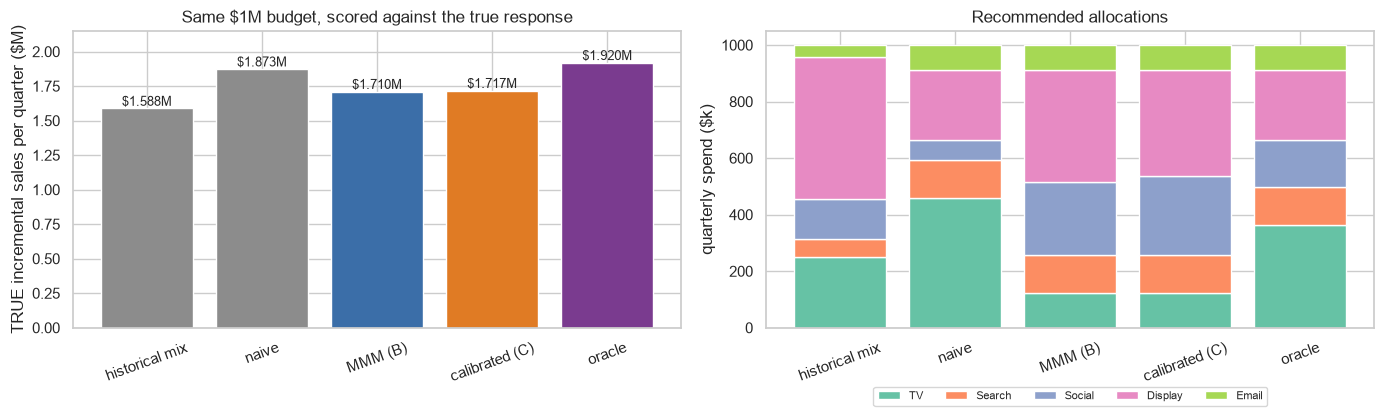

In [10]:
def show_budget(bt):
    v = bt.copy()
    for c in CHANNELS: v[c] = (v[c] / 1e3).round(0)
    v["true quarterly incremental sales"] = v["true quarterly incremental sales"].round(0)
    for c in ["vs naive", "vs historical", "share of achievable gain captured"]: v[c] = (v[c] * 100).round(1)
    return v.rename(columns={**{c: f"{c} ($k)" for c in CHANNELS}, "vs naive": "vs naive (%)", "vs historical": "vs current mix (%)",
                             "share of achievable gain captured": "headroom recovered (%)"})

bt, allocs = budget_table(world, train, NAIVE, {"MMM (B)": B, "calibrated (C)": C})
display(show_budget(bt))
n_, b_, c_ = (bt.loc[k, "true quarterly incremental sales"] for k in ["naive", "MMM (B)", "calibrated (C)"])
print(f"Calibrated MMM's budget delivered {c_/n_-1:+.1%} more TRUE incremental sales than the naive model's (uncalibrated MMM: {b_/n_-1:+.1%}).")
print(f"Headroom recovered: naive {bt.loc['naive','share of achievable gain captured']:.0%} | B {bt.loc['MMM (B)','share of achievable gain captured']:.0%} | "
      f"C {bt.loc['calibrated (C)','share of achievable gain captured']:.0%}  (the best possible budget would add {headroom(world, train):.1%} over the current mix)")

order = ["historical mix", "naive", "MMM (B)", "calibrated (C)", "oracle"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
vals = bt.loc[order, "true quarterly incremental sales"] / 1e6
ax[0].bar(order, vals, color=[COL["naive"], COL["naive"], COL["B"], COL["C"], COL["oracle"]]); ax[0].set_ylim(0, vals.max() * 1.12)       # zero baseline: truncated bars would exaggerate the differences
for i, v in enumerate(vals): ax[0].text(i, v, f"${v:.3f}M", ha="center", va="bottom", fontsize=9)
ax[0].set_ylabel("TRUE incremental sales per quarter ($M)"); ax[0].set_title("Same $1M budget, scored against the true response"); ax[0].tick_params(axis="x", rotation=20)
pal = sns.color_palette("Set2", 5); bottom = np.zeros(len(order))
for j, c in enumerate(CHANNELS):
    v = bt.loc[order, c].to_numpy() / 1e3; ax[1].bar(order, v, bottom=bottom, color=pal[j], label=c); bottom += v
ax[1].set_ylabel("quarterly spend ($k)"); ax[1].set_title("Recommended allocations"); ax[1].legend(fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.18)); ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(FIG / "05_budget_comparison.png", dpi=150, bbox_inches="tight"); plt.show()


## 8. Why did the MMM fail, and what fixes it? (main world)

Four things went wrong or could have, each tested directly:

* **Curve shape.** The truth uses Hill curves (TV is S-shaped); the default logistic curve cannot be S-shaped. **H** = same model
  with Hill saturation.
* **Over-attribution.** Check how much of total sales each model credits to marketing against the truth. **R** adds a weakly
  informative ROI-style prior (median ROI 2, same for every channel, centred on nothing the truth tells us); **HR** combines both.
* **Confounding.** **OC** hands the model the true unobserved demand shock as a control. If confounding were the whole story, error would collapse.
* **Calibration.** **C** (Social test), **D** (plus a test on the untested channel with the widest uncertainty, chosen by a rule fixed
  in advance), **E** (off-tests on every channel), **HE** / **HRE** (Hill, and Hill + ROI prior, with all-channel tests).


In [11]:
VAR = study.fit_variants(MAIN_SEED, world)
models = {"B: MMM": B, "H: Hill curves": VAR["H"], "R: ROI prior": VAR["R"], "HR: Hill + ROI prior": VAR["HR"],
          "OC: + true confounder": VAR["OC"], "C: + Social test": C, f"D: + Social & {NEXT} tests": D,
          "E: off-tests, all 5": E, "HE: Hill + all tests": VAR["HE"], "HRE: Hill + ROI prior + all tests": VAR["HRE"]}

def coverage(S, truth=TRUE_ROI):
    t = roi_table(S); return float(((t["lo94"] <= truth) & (truth <= t["hi94"])).mean())

bt_all, allocs_all = budget_table(world, train, NAIVE, models)
rows = [{"model": "naive regression", **{c: err(NAIVE, TRUE_ROI)[c] for c in CHANNELS}, "mean ROI error": err(NAIVE, TRUE_ROI).mean(),
         "headroom recovered": bt_all.loc["naive", "share of achievable gain captured"]}]
for k, S in models.items():
    e = err(roi_table(S)["mean"], TRUE_ROI)
    rows.append({"model": k, **{c: e[c] for c in CHANNELS}, "mean ROI error": e.mean(), "marketing share": S["marketing_share"],
                 "94% CIs containing truth": coverage(S), "R-hat": S["max_rhat"], "divergences": S["divergences"],
                 "headroom recovered": bt_all.loc[k, "share of achievable gain captured"]})
stress = pd.DataFrame(rows).set_index("model")
fmt = stress.copy()
for c in [*CHANNELS, "mean ROI error", "marketing share", "94% CIs containing truth", "headroom recovered"]:
    fmt[c] = (fmt[c] * 100).round(0)
print(f"(true marketing share of sales: {mk.sum()/train.sales.sum():.0%}; all columns are %, except R-hat and divergences)")
display(fmt)


(true marketing share of sales: 18%; all columns are %, except R-hat and divergences)


,TV,Search,Social,Display,Email,mean ROI error,headroom recovered,marketing share,94% CIs containing truth,R-hat,divergences
model,,,,,,,,,,,
naive regression,217.0,205.0,91.0,49.0,105.0,133.0,86.0,NaN,NaN,NaN,NaN
B: MMM,38.0,83.0,27.0,260.0,712.0,224.0,37.0,61.0,80.0,1.00,8.0
H: Hill curves,461.0,382.0,797.0,1430.0,1043.0,823.0,37.0,156.0,80.0,1.02,10.0
R: ROI prior,3.0,3.0,2.0,400.0,4.0,82.0,28.0,26.0,80.0,1.00,2.0
HR: Hill + ROI prior,9.0,29.0,20.0,395.0,44.0,99.0,-9.0,22.0,100.0,1.01,1.0
OC: + true confounder,281.0,55.0,34.0,56.0,162.0,117.0,96.0,35.0,100.0,1.01,18.0
C: + Social test,36.0,82.0,22.0,248.0,720.0,221.0,39.0,61.0,80.0,1.01,11.0
D: + Social & Email tests,19.0,112.0,18.0,260.0,9.0,84.0,39.0,28.0,100.0,1.01,0.0
"E: off-tests, all 5",47.0,66.0,30.0,85.0,10.0,48.0,91.0,25.0,100.0,1.00,0.0


In [12]:
def marginal_roi(S):
    return {c: (curve_draws(S["params"], c, cur[c] + 1000) - curve_draws(S["params"], c, cur[c])).mean() / 1000 for c in CHANNELS}

mt = pd.DataFrame({"true avg ROI": TRUE_ROI, "true MARGINAL ROI": pd.Series(marg),
                   "B": pd.Series(marginal_roi(B)), "C": pd.Series(marginal_roi(C)), "E (off-tests)": pd.Series(marginal_roi(E)),
                   "HE (Hill + tests)": pd.Series(marginal_roi(VAR["HE"])), "HRE": pd.Series(marginal_roi(VAR["HRE"]))}).round(2)
display(mt)
rank = lambda s: " > ".join(s.sort_values(ascending=False).index)
print("Channel ranking by marginal ROI at current spend (what a budget optimizer follows):")
for col in ["true MARGINAL ROI", "B", "C", "E (off-tests)", "HE (Hill + tests)", "HRE"]:
    print(f"  {col:20s} {rank(mt[col])}")


,true avg ROI,true MARGINAL ROI,B,C,E (off-tests),HE (Hill + tests),HRE
TV,1.36,1.30,0.59,0.68,1.65,0.56,0.89
Search,4.85,2.46,7.10,6.95,7.21,9.93,4.89
Social,1.90,1.05,1.88,1.99,2.11,1.70,1.26
Display,0.37,0.21,1.05,0.98,0.59,0.73,1.13
Email,9.82,3.77,26.62,26.75,8.67,30.56,7.57


Channel ranking by marginal ROI at current spend (what a budget optimizer follows):
  true MARGINAL ROI    Email > Search > TV > Social > Display
  B                    Email > Search > Social > Display > TV
  C                    Email > Search > Social > Display > TV
  E (off-tests)        Email > Search > Social > TV > Display
  HE (Hill + tests)    Email > Search > Social > Display > TV
  HRE                  Email > Search > Social > Display > TV


## 9. Robustness: six fresh worlds with different true parameters

Each world draws its own true adstock, saturation and ROI per channel, its own noise, spend paths, test randomization and test
errors. None of these worlds was used while building the pipeline. For each: the naive model, B, C, D (C plus a test on the
most uncertain untested channel), E (off-tests on every channel), and three variants chosen from the main-world results:
R (ROI prior), HE (Hill curves + tests on every channel) and HRE (Hill + ROI prior + tests on every channel).


In [13]:
ROBUST_EXTRA = study.ROBUST_EXTRA
NAMES = {"B": "MMM (B)", "C": "calibrated (C)", "D": "C + next test (D)", "E": "tests on all 5 (E)"}
EXTRA_NAMES = {"R": "ROI prior (R)", "HE": "Hill + all tests (HE)", "HRE": "Hill + ROI prior\n+ all tests (HRE)"}

def evaluate_world(seed, world_=None):
    w = world_ or random_world(seed)
    tr = w["df"].iloc[:N_TRAIN]; troi = pd.Series(true_roi(w)); nv = naive_roi(tr)
    core_ = study.fit_core(seed, w)
    sums = {NAMES[k]: core_[k] for k in "BCDE"}
    if ROBUST_EXTRA:
        sums.update({EXTRA_NAMES[k]: v for k, v in study.fit_variants(seed, w, only=ROBUST_EXTRA).items()})
    bt_, _ = budget_table(w, tr, nv, sums)
    off_, half_ = study.all_tests(seed, w)
    rows = []
    for k in ["naive", *sums]:
        est = nv if k == "naive" else roi_table(sums[k])["mean"]; e = err(est, troi)
        rows.append(dict(seed=seed, model=k, roi_err=e.mean(), social_err=e["Social"], display_err=e["Display"],
                         coverage=np.nan if k == "naive" else coverage(sums[k], troi),
                         marketing_share=np.nan if k == "naive" else sums[k]["marketing_share"],
                         vs_naive=bt_.loc[k, "vs naive"], vs_current=bt_.loc[k, "vs historical"],
                         recovered=bt_.loc[k, "share of achievable gain captured"], headroom=headroom(w, tr),
                         next_test=core_["_next"], wrong_sign=sum(t["wrong_sign"] for t in [*off_.values()])))
    return pd.DataFrame(rows)

robust = pd.concat([evaluate_world(s) for s in ROBUST_SEEDS], ignore_index=True)
MODELS = ["naive", *NAMES.values(), *[EXTRA_NAMES[k] for k in ROBUST_EXTRA]]
agg = robust.groupby("model")[["roi_err", "social_err", "display_err", "coverage", "marketing_share", "vs_naive", "vs_current", "recovered"]].mean().loc[MODELS]
display((agg * 100).round(1).rename(columns={"roi_err": "ROI error (%)", "social_err": "Social error (%)", "display_err": "Display error (%)",
        "coverage": "94% CIs containing truth (%)", "marketing_share": "marketing share (%)", "vs_naive": "budget vs naive (%)",
        "vs_current": "budget vs current mix (%)", "recovered": "headroom recovered (%)"}))
hw = robust.drop_duplicates("seed").set_index("seed").headroom
print(f"Headroom per world (true curves vs current mix): {hw.mul(100).round(1).to_dict()}  | mean {hw.mean():.1%}")
print("Channel chosen for the follow-up test, per world:", robust.drop_duplicates('seed').set_index('seed').next_test.to_dict())


,ROI error (%),Social error (%),Display error (%),94% CIs containing truth (%),marketing share (%),budget vs naive (%),budget vs current mix (%),headroom recovered (%)
model,,,,,,,,
naive,220.6,200.5,169.3,NaN,NaN,0.0,8.2,56.9
MMM (B),264.7,144.0,52.6,73.3,57.0,3.3,11.9,77.9
calibrated (C),255.3,84.5,38.8,70.0,56.0,3.5,12.0,79.6
C + next test (D),182.3,84.1,42.1,73.3,41.9,3.0,11.5,75.4
tests on all 5 (E),71.2,98.8,56.0,56.7,27.4,2.7,11.1,75.7
ROI prior (R),151.7,125.9,60.7,86.7,34.6,-0.1,8.1,52.6
Hill + all tests (HE),69.8,96.7,44.2,76.7,27.3,3.7,12.2,80.2
Hill + ROI prior\n+ all tests (HRE),66.3,89.3,51.6,83.3,24.0,2.5,10.9,74.3


Headroom per world (true curves vs current mix): {11: 11.2, 12: 16.5, 13: 17.0, 14: 16.1, 15: 19.8, 16: 9.0}  | mean 14.9%
Channel chosen for the follow-up test, per world: {11: 'Email', 12: 'Email', 13: 'Email', 14: 'Email', 15: 'Email', 16: 'Email'}


Across 6 fresh worlds (each with its own true parameters), compared with the plain MMM (B):


,lower ROI error than B,lower Social error than B,lower Display error than B,budget beats current mix,"headroom recovered, mean","headroom recovered, min-max",more headroom recovered than B
model,,,,,,,
MMM (B),0/6,0/6,0/6,6/6,78%,36% to 98%,0/6
calibrated (C),4/6,6/6,3/6,6/6,80%,54% to 99%,4/6
C + next test (D),6/6,6/6,3/6,6/6,75%,40% to 99%,3/6
tests on all 5 (E),6/6,4/6,2/6,6/6,76%,57% to 91%,4/6
ROI prior (R),6/6,3/6,4/6,5/6,53%,-6% to 89%,0/6
Hill + all tests (HE),6/6,4/6,4/6,6/6,80%,65% to 96%,3/6
Hill + ROI prior\n+ all tests (HRE),6/6,5/6,2/6,6/6,74%,32% to 93%,1/6


  Naive regression: mean headroom recovered 57% (range 35% to 70%); budget beats current mix in 6/6


  True marketing share of sales: 17% on average


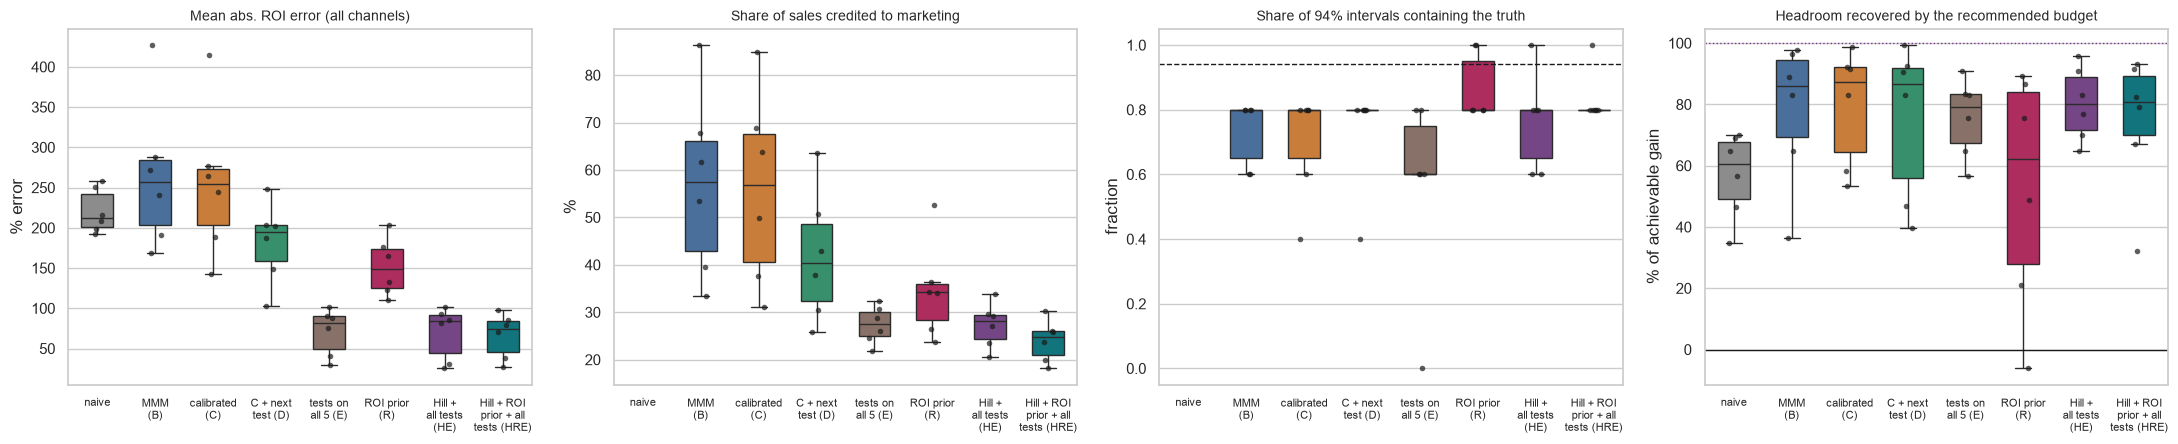

roi_err  social_err  display_err  \
seed model                                                                   
11   naive                                  198.0       115.0        222.0   
     MMM (B)                                241.0        17.0        121.0   
     calibrated (C)                         245.0         6.0         74.0   
     C + next test (D)                      187.0         5.0         92.0   
     tests on all 5 (E)                      30.0        39.0          2.0   
     ROI prior (R)                          133.0        32.0        217.0   
     Hill + all tests (HE)                   25.0        48.0          2.0   
     Hill + ROI prior\n+ all tests (HRE)     26.0        38.0          3.0   
12   naive                                  208.0       407.0         55.0   
     MMM (B)                                168.0       392.0         56.0   
     calibrated (C)                         142.0       248.0         52.0   
     C + next test (D)                      103.0       247.0         52.0   
     tests on all 5 (E)                      88.0       241.0         11.0   
     ROI prior (R)                          110.0       443.0         23.0   
     Hill + all tests (HE)                   93.0       248.0         36.0   
     Hill + ROI prior\n+ all tests (HRE)     86.0       242.0         42.0   
13   naive                                  258.0       149.0        362.0   
     MMM (B)                                191.0       107.0         12.0   
     calibrated (C)                         189.0         4.0         17.0   
     C + next test (D)                      148.0         3.0         15.0   
     tests on all 5 (E)                      41.0        10.0         40.0   
     ROI prior (R)                          122.0        90.0         69.0   
     Hill + all tests (HE)                   31.0        10.0         21.0   
     Hill + ROI prior\n+ all tests (HRE)     38.0         5.0         31.0   
14   naive                                  216.0       287.0        131.0   
     MMM (B)                                272.0       140.0         57.0   
     calibrated (C)                         277.0        69.0         12.0   
     C + next test (D)                      249.0        69.0         11.0   
     tests on all 5 (E)                      76.0        67.0        110.0   
     ROI prior (R)                          176.0       100.0         19.0   
     Hill + all tests (HE)                   86.0        47.0         51.0   
     Hill + ROI prior\n+ all tests (HRE)     80.0        56.0         58.0   
15   naive                                  250.0       153.0         69.0   
     MMM (B)                                427.0        41.0         42.0   
     calibrated (C)                         414.0        27.0         43.0   
     C + next test (D)                      202.0        27.0         45.0   
     tests on all 5 (E)                     101.0        18.0        144.0   
     ROI prior (R)                          204.0        50.0         15.0   
     Hill + all tests (HE)                  101.0        22.0        136.0   
     Hill + ROI prior\n+ all tests (HRE)     98.0        36.0        145.0   
16   naive                                  193.0        92.0        177.0   
     MMM (B)                                288.0       166.0         27.0   
     calibrated (C)                         265.0       154.0         35.0   
     C + next test (D)                      203.0       154.0         37.0   
     tests on all 5 (E)                      90.0       218.0         31.0   
     ROI prior (R)                          165.0        41.0         20.0   
     Hill + all tests (HE)                   82.0       206.0         20.0   
     Hill + ROI prior\n+ all tests (HRE)     70.0       160.0         31.0   

                                          coverage  marketing_share  vs_naive  \
seed model                                                  

In [14]:
piv = lambda col: robust.pivot(index="seed", columns="model", values=col)[MODELS]
n = len(ROBUST_SEEDS)
print(f"Across {n} fresh worlds (each with its own true parameters), compared with the plain MMM (B):")
rows = []
for m_ in MODELS[1:]:
    rows.append({"model": m_,
                 "lower ROI error than B": f"{int((piv('roi_err')[m_] < piv('roi_err')['MMM (B)']).sum())}/{n}",
                 "lower Social error than B": f"{int((piv('social_err')[m_] < piv('social_err')['MMM (B)']).sum())}/{n}",
                 "lower Display error than B": f"{int((piv('display_err')[m_] < piv('display_err')['MMM (B)']).sum())}/{n}",
                 "budget beats current mix": f"{int((piv('vs_current')[m_] > 0).sum())}/{n}",
                 "headroom recovered, mean": f"{piv('recovered')[m_].mean():.0%}",
                 "headroom recovered, min-max": f"{piv('recovered')[m_].min():.0%} to {piv('recovered')[m_].max():.0%}",
                 "more headroom recovered than B": f"{int((piv('recovered')[m_] > piv('recovered')['MMM (B)']).sum())}/{n}"})
display(pd.DataFrame(rows).set_index("model"))
print(f"  Naive regression: mean headroom recovered {piv('recovered')['naive'].mean():.0%} (range {piv('recovered')['naive'].min():.0%} to {piv('recovered')['naive'].max():.0%}); "
      f"budget beats current mix in {int((piv('vs_current')['naive'] > 0).sum())}/{n}")
print(f"  True marketing share of sales: {np.mean([sum(random_world(s_)['df'].iloc[:N_TRAIN][f'contrib_{c}'].sum() for c in CHANNELS) / random_world(s_)['df'].iloc[:N_TRAIN].sales.sum() for s_ in ROBUST_SEEDS]):.0%} on average")

SHORT = {"naive": "naive", "MMM (B)": "MMM\n(B)", "calibrated (C)": "calibrated\n(C)", "C + next test (D)": "C + next\ntest (D)",
         "tests on all 5 (E)": "tests on\nall 5 (E)", EXTRA_NAMES["R"]: "ROI prior\n(R)", EXTRA_NAMES["HE"]: "Hill +\nall tests\n(HE)",
         EXTRA_NAMES["HRE"]: "Hill + ROI\nprior + all\ntests (HRE)"}
short = lambda m: SHORT.get(m, m)
pal_ = [COL["naive"], COL["B"], COL["C"], COL["D"], COL["E"], "#c2185b", "#7a3b8f", "#00838f", "#555"][:len(MODELS)]
fig, ax = plt.subplots(1, 4, figsize=(22, 4.6))
for a_, col_, title, ylab, scale in [(ax[0], "roi_err", "Mean abs. ROI error (all channels)", "% error", 100),
                                      (ax[1], "marketing_share", "Share of sales credited to marketing", "%", 100),
                                      (ax[2], "coverage", "Share of 94% intervals containing the truth", "fraction", 1),
                                      (ax[3], "recovered", "Headroom recovered by the recommended budget", "% of achievable gain", 100)]:
    d_ = robust.assign(v=robust[col_] * scale, m=robust.model.map(short))
    sns.boxplot(data=d_, x="m", y="v", order=[short(m) for m in MODELS], palette=pal_, ax=a_, showfliers=False, width=0.55)
    sns.stripplot(data=d_, x="m", y="v", order=[short(m) for m in MODELS], color="k", size=4, ax=a_, alpha=0.7)
    a_.set_title(title, fontsize=10); a_.set_xlabel(""); a_.set_ylabel(ylab); a_.tick_params(axis="x", labelsize=8)
ax[2].axhline(0.94, color="k", ls="--", lw=1); ax[3].axhline(0, color="k", lw=1); ax[3].axhline(100, color=COL["oracle"], ls=":", lw=1)
plt.tight_layout(); plt.savefig(FIG / "06_robustness.png", dpi=150, bbox_inches="tight"); plt.show()
display(robust.assign(roi_err=(robust.roi_err*100).round(0), social_err=(robust.social_err*100).round(0), display_err=(robust.display_err*100).round(0),
                      coverage=(robust.coverage*100).round(0), marketing_share=(robust.marketing_share*100).round(0),
                      vs_naive=(robust.vs_naive*100).round(1), vs_current=(robust.vs_current*100).round(1),
                      recovered=(robust.recovered*100).round(0), headroom=(robust.headroom*100).round(1)).drop(columns=["wrong_sign"]).set_index(["seed", "model"]))


## 10. One-page recommendation for a marketing VP

*(Written from the main world. Dollar figures are model estimates; where the simulation lets us check against the truth, that is
shown too, which you could never do with real data. The model reported on is chosen by a rule fixed in advance: the
experiment-based model with the lowest mean ROI error across the six fresh worlds. Every number below is computed.)*


In [15]:
cands = {"tests on all 5 (E)": ("E: off-tests, all 5", E), "Hill + all tests (HE)": ("HE: Hill + all tests", VAR["HE"]),
         EXTRA_NAMES["HRE"]: ("HRE: Hill + ROI prior + all tests", VAR["HRE"])}
memo_name = min(cands, key=lambda k: agg.loc[k, "roi_err"])
memo_key, S = cands[memo_name]
label = memo_name.replace("\n", " ")

cur_q = {c: v * 13 for c, v in current_mix_weekly(train).items()}
rec_q = {c: v * 13 for c, v in allocs_all[memo_key].items()}
hist_pred = sum(curve_draws(S["params"], c, cur_q[c] / 13) for c in CHANNELS) * 13
rec_pred = sum(curve_draws(S["params"], c, rec_q[c] / 13) for c in CHANNELS) * 13
gain = rec_pred - hist_pred; lo, hi = hdi(gain); p_pos = (gain > 0).mean()
cur_sales = bt_all.loc["historical mix", "true quarterly incremental sales"]
truth_gain = bt_all.loc[memo_key, "true quarterly incremental sales"] - cur_sales

rt = roi_table(S)
moves = pd.DataFrame({"now ($k/qtr)": pd.Series(cur_q) / 1e3, "suggested ($k/qtr)": pd.Series(rec_q) / 1e3})
moves["change (%)"] = (moves["suggested ($k/qtr)"] / moves["now ($k/qtr)"] - 1) * 100
moves["model ROI (94% interval)"] = [f"{rt.loc[c,'mean']:.1f} ({rt.loc[c,'lo94']:.1f}-{rt.loc[c,'hi94']:.1f})" for c in moves.index]
moves["true ROI (simulation only)"] = TRUE_ROI.round(1)

f = robust[robust.model == memo_name]
wins = int((f.vs_current > 0).sum())
base = robust[robust.model == "MMM (B)"]
spend_tot = train[CHANNELS].sum()
widths = {c: (lambda a, b: b - a)(*hdi(S["roi"][c].to_numpy() * spend_tot[c])) for c in CHANNELS}
next_ch = max(widths, key=widths.get)

stance = ("**Reallocate toward the suggested mix, in stages, and keep testing.**" if wins == n
          else "**Treat the suggested mix with caution: it did not beat the current mix in every simulated world.**")

memo = f'''
### Recommendation for next quarter ($1M budget)

{stance}

**What to do.** Move toward the mix below (model: {label}). It is the experiment-based model with the lowest ROI error across the fresh worlds.

{moves.round(1).to_markdown()}

**Why we believe it, and how much.**
* In the main world the model predicts the move adds **{gain.mean()/1e3:+,.0f}k** of quarterly incremental sales (94% interval {lo/1e3:+,.0f}k to {hi/1e3:+,.0f}k; {p_pos:.0%} of draws positive).
  The true change is **{truth_gain/1e3:+,.0f}k**, which is {bt_all.loc[memo_key,'share of achievable gain captured']:.0%} of the achievable gain (the best possible mix adds {headroom(world, train):.1%} over the current one).
* Across {n} independent simulated worlds the same recipe beat the current mix in **{wins} of {n}**, recovering on average {f.recovered.mean():.0%} of the achievable gain
  (range {f.recovered.min():.0%} to {f.recovered.max():.0%}). The uncalibrated MMM recovered {base.recovered.mean():.0%} on average (range {base.recovered.min():.0%} to {base.recovered.max():.0%}) and a naive regression {piv('recovered')['naive'].mean():.0%}.
  So the results are good on average but vary a lot from world to world.
* ROI *levels* are better than the plain MMM's, not perfect: mean ROI error {f.roi_err.mean():.0%} vs. {base.roi_err.mean():.0%}; the model credits {f.marketing_share.mean():.0%} of sales to marketing (truth {np.mean([sum(random_world(s_)['df'].iloc[:N_TRAIN][f'contrib_{c}'].sum() for c in CHANNELS) / random_world(s_)['df'].iloc[:N_TRAIN].sales.sum() for s_ in ROBUST_SEEDS]):.0%}).
  Its stated 94% intervals contained the true ROI {f.coverage.mean():.0%} of the time, a bit narrow.
* Better ROI estimates did not by themselves make budgets better: the plain MMM's budgets recovered about as much headroom ({base.recovered.mean():.0%}) as the all-channel-calibrated ones ({f.recovered.mean():.0%}).
  Calibrating only one channel (Social) fixed that channel's ROI (error {piv('social_err')['MMM (B)'].mean():.0%} to {piv('social_err')['calibrated (C)'].mean():.0%} across worlds) and little else.

**What to test next.** {next_ch} has the widest uncertainty in incremental sales under this model (94% interval ${widths[next_ch]/1e6:.1f}M wide over three years). Re-test it with
a *second spend level* (e.g. a halve test as well as a switch-off) and a window long enough to cover carry-over (the first weeks of a cut under-measure slow channels): a switch-off test pins down
average return, but budgets follow marginal return.

**Ask of finance:** approve a recurring test budget. The model's value comes from experiments that keep it honest.
'''
display(Markdown(memo))



### Recommendation for next quarter ($1M budget)

**Reallocate toward the suggested mix, in stages, and keep testing.**

**What to do.** Move toward the mix below (model: Hill + ROI prior + all tests (HRE)). It is the experiment-based model with the lowest ROI error across the fresh worlds.

|         |   now ($k/qtr) |   suggested ($k/qtr) |   change (%) | model ROI (94% interval)   |   true ROI (simulation only) |
|:--------|---------------:|---------------------:|-------------:|:---------------------------|-----------------------------:|
| TV      |          248.9 |                212.4 |        -14.6 | 1.7 (0.5-3.1)              |                          1.4 |
| Search  |           65.9 |                131.8 |        100   | 5.0 (1.3-9.3)              |                          4.9 |
| Social  |          140.5 |                183.7 |         30.7 | 1.9 (0.5-3.4)              |                          1.9 |
| Display |          501.4 |                385.3 |        -23.1 | 0.8 (0.3-1.3)              |                          0.4 |
| Email   |           43.4 |                 86.8 |        100   | 7.3 (1.2-13.1)             |                          9.8 |

**Why we believe it, and how much.**
* In the main world the model predicts the move adds **+366k** of quarterly incremental sales (94% interval -154k to +1,113k; 86% of draws positive).
  The true change is **+208k**, which is 63% of the achievable gain (the best possible mix adds 20.9% over the current one).
* Across 6 independent simulated worlds the same recipe beat the current mix in **6 of 6**, recovering on average 74% of the achievable gain
  (range 32% to 93%). The uncalibrated MMM recovered 78% on average (range 36% to 98%) and a naive regression 57%.
  So the results are good on average but vary a lot from world to world.
* ROI *levels* are better than the plain MMM's, not perfect: mean ROI error 66% vs. 265%; the model credits 24% of sales to marketing (truth 17%).
  Its stated 94% intervals contained the true ROI 83% of the time, a bit narrow.
* Better ROI estimates did not by themselves make budgets better: the plain MMM's budgets recovered about as much headroom (78%) as the all-channel-calibrated ones (74%).
  Calibrating only one channel (Social) fixed that channel's ROI (error 144% to 84% across worlds) and little else.

**What to test next.** TV has the widest uncertainty in incremental sales under this model (94% interval $7.8M wide over three years). Re-test it with
a *second spend level* (e.g. a halve test as well as a switch-off) and a window long enough to cover carry-over (the first weeks of a cut under-measure slow channels): a switch-off test pins down
average return, but budgets follow marginal return.

**Ask of finance:** approve a recurring test budget. The model's value comes from experiments that keep it honest.


## What this does and doesn't show

See the README for the full list of caveats. In short: one family of simulated worlds (six fresh ones plus a worked example), one MMM implementation,
a planning rule that lets channels halve or double, and one geo-test design. It shows how the pieces interact, not a universal verdict on MMM or on calibration.
